# 06 · LSTM Forecasting

A recurrent neural network learns demand patterns from a sliding 28-day window. Requires TensorFlow (`pip install -r requirements-full.txt`).

In [1]:
import sys, warnings, logging
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)

from src.config import *
from src.ingestion.etl import load_processed
D = load_processed()
tx, customers, products, inventory = D["transactions"], D["customers"], D["products"], D["inventory"]
daily = D["daily"]
print(f"Loaded {len(tx):,} clean transaction lines | {tx.customer_id.nunique():,} customers | "
      f"{tx.order_date.min().date()} -> {tx.order_date.max().date()}")

Loaded 54,339 clean transaction lines | 1,455 customers | 2024-01-01 -> 2025-12-31


In [2]:
series = daily.set_index("date")["units"].astype(float)
train, test = series.iloc[:-HOLDOUT_DAYS], series.iloc[-HOLDOUT_DAYS:]

## 1. Sliding windows

In [3]:
from src.forecasting.lstm_model import _windows
mu, sd = train.mean(), train.std()
X, y = _windows(((train - mu) / sd).values.astype("float32"), 28)
print("X:", X.shape, "(samples, timesteps, features) | y:", y.shape)

X: (643, 28, 1) (samples, timesteps, features) | y: (643,)


## 2. Train (small network + early stopping) and forecast the holdout recursively

In [4]:
import time
from src.forecasting.lstm_model import forecast_lstm
from src.forecasting.ensemble import regression_metrics
t0 = time.time()
pred = forecast_lstm(train, HOLDOUT_DAYS, window=28, epochs=40, verbose=0)
print(f"trained + forecast in {time.time() - t0:.0f}s")
metrics = regression_metrics(test.values, pred["yhat"].values)
print({k: round(v, 3) for k, v in metrics.items()})

trained + forecast in 11s
{'mae': 17.623, 'rmse': 23.873, 'wape': 0.138, 'bias': -12.855}


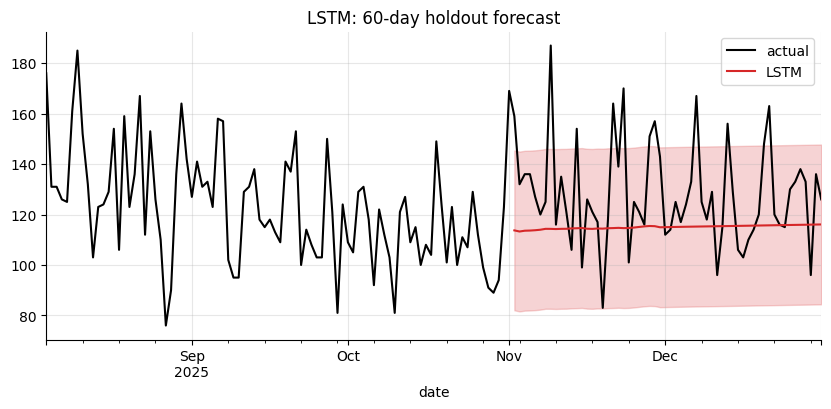

In [5]:
ax = series.tail(150).plot(label="actual", color="k")
ax.plot(pred["ds"], pred["yhat"], label="LSTM", color="C3")
ax.fill_between(pred["ds"], pred["yhat_lower"], pred["yhat_upper"], alpha=.2, color="C3")
plt.legend(); plt.title("LSTM: 60-day holdout forecast"); plt.show()

## 3. Observations
- The LSTM tends to **under-forecast** over long recursive horizons (negative bias) because each step feeds on its own prediction.
- On its own it is *not* the most accurate model here - but its errors are different from Prophet's and the GBM's, which is exactly why it adds value in the **hybrid ensemble** (notebook 08).